# Reviewer 1 Analysis — LOSO Diagnostic Analysis

This notebook is a separate diagnostic analysis created to address Reviewer #1 comments.

The original UCL analysis notebook (`ucl.ipynb`) is not modified.

This notebook reproduces the original XGBoost + LOSO protocol and additionally calculates:

1. Mean subject-level AUC with standard deviation and 95% CI
2. Mean subject-level F1 with standard deviation and 95% CI
3. Per-subject pain/non-pain sample counts
4. Per-subject AUC, F1, precision, recall
5. Per-subject confusion-matrix counts
6. Broad/Combined-label pooled out-of-fold AUC
7. PIPP-confirmed pooled out-of-fold AUC
8. Class-distribution diagnostics
9. Fixed-threshold F1 sensitivity analysis

Important:
- The original LOSO protocol is preserved.
- Scaling is fitted only on training subjects.
- `scale_pos_weight` is calculated separately within each training fold.
- The original XGBoost hyperparameters are retained.
- No threshold is optimized on a held-out subject.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix
)

import xgboost as xgb


# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_ROOT = r"C:\Users\Asus\OneDrive\Desktop\neopain-research"

UCL_RAW_PATH = os.path.join(
    PROJECT_ROOT,
    "data",
    "raw",
    "UCL"
)

PICS_RAW_PATH = os.path.join(
    PROJECT_ROOT,
    "data",
    "raw",
    "PICS"
)

PROCESSED_PATH = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed"
)

RESULTS_PATH = os.path.join(
    PROJECT_ROOT,
    "results",
    "reviewer1"
)

FEATURE_FILE = os.path.join(
    PROCESSED_PATH,
    "ucl_feature_matrix_clean.csv"
)

os.makedirs(RESULTS_PATH, exist_ok=True)


print("=" * 70)
print("PROJECT PATHS")
print("=" * 70)

print("Project root :", PROJECT_ROOT)
print("UCL raw path :", UCL_RAW_PATH)
print("PICS path    :", PICS_RAW_PATH)
print("Feature file :", FEATURE_FILE)
print("Results path :", RESULTS_PATH)

if not os.path.exists(FEATURE_FILE):
    raise FileNotFoundError(
        f"\nFeature matrix not found:\n{FEATURE_FILE}"
    )

print("\nFeature matrix found successfully.")

PROJECT PATHS
Project root : C:\Users\Asus\OneDrive\Desktop\neopain-research
UCL raw path : C:\Users\Asus\OneDrive\Desktop\neopain-research\data\raw\UCL
PICS path    : C:\Users\Asus\OneDrive\Desktop\neopain-research\data\raw\PICS
Feature file : C:\Users\Asus\OneDrive\Desktop\neopain-research\data\processed\ucl_feature_matrix_clean.csv
Results path : C:\Users\Asus\OneDrive\Desktop\neopain-research\results\reviewer1

Feature matrix found successfully.


In [2]:
# ============================================================
# LOAD EXISTING FEATURE MATRIX
# ============================================================

df = pd.read_csv(FEATURE_FILE)

print("=" * 70)
print("FEATURE MATRIX")
print("=" * 70)

print("Shape:", df.shape)

print("\nNumber of unique subjects:",
      df["Record identifier"].nunique())

print("\nColumns:")
for col in df.columns:
    print(" -", col)

print("\nFirst 5 rows:")
display(df.head())

FEATURE MATRIX
Shape: (295, 78)

Number of unique subjects: 105

Columns:
 - Cz_delta_post
 - Cz_theta_post
 - Cz_alpha_post
 - Cz_beta_post
 - Cz_delta_change
 - Cz_erp_peak
 - Cz_erp_mean
 - Cz_erp_early
 - Cz_erp_late
 - CPz_delta_post
 - CPz_theta_post
 - CPz_alpha_post
 - CPz_beta_post
 - CPz_delta_change
 - CPz_erp_peak
 - CPz_erp_mean
 - CPz_erp_early
 - CPz_erp_late
 - C3_delta_post
 - C3_theta_post
 - C3_alpha_post
 - C3_beta_post
 - C3_delta_change
 - C3_erp_peak
 - C3_erp_mean
 - C3_erp_early
 - C3_erp_late
 - C4_delta_post
 - C4_theta_post
 - C4_alpha_post
 - C4_beta_post
 - C4_delta_change
 - C4_erp_peak
 - C4_erp_mean
 - C4_erp_early
 - C4_erp_late
 - CP3_delta_post
 - CP3_theta_post
 - CP3_alpha_post
 - CP3_beta_post
 - CP3_delta_change
 - CP3_erp_peak
 - CP3_erp_mean
 - CP3_erp_early
 - CP3_erp_late
 - CP4_delta_post
 - CP4_theta_post
 - CP4_alpha_post
 - CP4_beta_post
 - CP4_delta_change
 - CP4_erp_peak
 - CP4_erp_mean
 - CP4_erp_early
 - CP4_erp_late
 - gfp_mean_post


,Cz_delta_post,Cz_theta_post,Cz_alpha_post,Cz_beta_post,Cz_delta_change,Cz_erp_peak,Cz_erp_mean,Cz_erp_early,Cz_erp_late,CPz_delta_post,...,pipp_label,Total PIPP score,age_group,on_analgesic,pipp_baseline_hr,pipp_max_hr,pipp_hr_change,pipp_baseline_spo2,pipp_min_spo2,pipp_spo2_drop
0,25112.441895,7876.973877,0.0,17664.023399,166.863186,8956.551758,7621.630859,8905.380859,8956.551758,2353.247147,...,NaN,NaN,G3_oldest,0,142.0,148.0,4.0,97.0,96.0,1.0
1,452.657609,70.232365,0.0,10.375754,3.274168,2608.627197,2428.759766,2552.747803,2608.627197,664.781250,...,NaN,NaN,G3_oldest,0,142.0,148.0,4.0,97.0,96.0,1.0
2,432.449140,98.971399,0.0,5.926552,5.633399,2707.660156,2555.308105,2614.796143,2707.660156,528.509915,...,NaN,NaN,G3_oldest,0,142.0,148.0,4.0,97.0,96.0,1.0
3,1153.322324,138.972462,0.0,2.064934,48.468662,721.484436,-678.756592,721.484436,706.970703,822.140883,...,NaN,NaN,G3_oldest,0,142.0,148.0,4.0,97.0,96.0,1.0
4,993.301449,144.186371,0.0,5.198114,7.619309,16298.562500,16205.771484,16298.562500,16280.084961,1254.049673,...,NaN,NaN,G3_oldest,0,142.0,148.0,4.0,97.0,96.0,1.0


In [3]:
# ============================================================
# LABEL INSPECTION
# ============================================================

print("=" * 70)
print("LABEL INFORMATION")
print("=" * 70)

print("\nPIPP label availability:")
print(
    df["pipp_label"]
    .notna()
    .value_counts()
)

print("\nPIPP label distribution:")
print(
    df["pipp_label"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nCondition-based pain label distribution:")
print(
    df["pain_label"]
    .value_counts(dropna=False)
    .sort_index()
)

LABEL INFORMATION

PIPP label availability:
pipp_label
True     210
False     85
Name: count, dtype: int64

PIPP label distribution:
pipp_label
0.0    165
1.0     45
NaN     85
Name: count, dtype: int64

Condition-based pain label distribution:
pain_label
0    192
1    103
Name: count, dtype: int64


In [4]:
# ============================================================
# FEATURE / METADATA COLUMNS
# ============================================================

meta_cols = [
    "mat_path",
    "EEG file name",
    "Record identifier",
    "condition",
    "pain_label",
    "pipp_label",
    "Total PIPP score",
    "age_group",
    "on_analgesic"
]

feat_cols = [
    c for c in df.columns
    if c not in meta_cols
]

print("Number of feature columns:", len(feat_cols))

print("\nFeature columns:")
for col in feat_cols:
    print(" -", col)


# ============================================================
# BROAD / COMBINED LABEL
# ============================================================
#
# This matches the existing Cell 10 scheme:
#
# PIPP label where available
# condition-based pain label otherwise
#
# ============================================================

df["final_label"] = (
    df["pipp_label"]
    .fillna(df["pain_label"])
)


print("\nCombined-label distribution:")
print(
    df["final_label"]
    .value_counts(dropna=False)
    .sort_index()
)


# ============================================================
# PIPP-CONFIRMED DATASET
# ============================================================

df_pipp = df[
    df["pipp_label"].notna()
].copy()

print("\nPIPP-confirmed distribution:")
print(
    df_pipp["pipp_label"]
    .value_counts(dropna=False)
    .sort_index()
)

Number of feature columns: 69

Feature columns:
 - Cz_delta_post
 - Cz_theta_post
 - Cz_alpha_post
 - Cz_beta_post
 - Cz_delta_change
 - Cz_erp_peak
 - Cz_erp_mean
 - Cz_erp_early
 - Cz_erp_late
 - CPz_delta_post
 - CPz_theta_post
 - CPz_alpha_post
 - CPz_beta_post
 - CPz_delta_change
 - CPz_erp_peak
 - CPz_erp_mean
 - CPz_erp_early
 - CPz_erp_late
 - C3_delta_post
 - C3_theta_post
 - C3_alpha_post
 - C3_beta_post
 - C3_delta_change
 - C3_erp_peak
 - C3_erp_mean
 - C3_erp_early
 - C3_erp_late
 - C4_delta_post
 - C4_theta_post
 - C4_alpha_post
 - C4_beta_post
 - C4_delta_change
 - C4_erp_peak
 - C4_erp_mean
 - C4_erp_early
 - C4_erp_late
 - CP3_delta_post
 - CP3_theta_post
 - CP3_alpha_post
 - CP3_beta_post
 - CP3_delta_change
 - CP3_erp_peak
 - CP3_erp_mean
 - CP3_erp_early
 - CP3_erp_late
 - CP4_delta_post
 - CP4_theta_post
 - CP4_alpha_post
 - CP4_beta_post
 - CP4_delta_change
 - CP4_erp_peak
 - CP4_erp_mean
 - CP4_erp_early
 - CP4_erp_late
 - gfp_mean_post
 - gfp_max_post
 - n_chann

In [5]:
# ============================================================
# ORIGINAL XGBOOST PARAMETERS
# ============================================================

XGB_PARAMS = dict(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    verbosity=0
)

print("XGBoost parameters:")
for key, value in XGB_PARAMS.items():
    print(f"{key}: {value}")

XGBoost parameters:
n_estimators: 300
max_depth: 3
learning_rate: 0.03
min_child_weight: 3
subsample: 0.8
colsample_bytree: 0.8
eval_metric: logloss
random_state: 42
verbosity: 0


In [6]:
# ============================================================
# LOSO DIAGNOSTIC FUNCTION
# ============================================================

def run_loso_diagnostics(
    dataframe,
    label_column,
    scheme_name
):
    
    work = dataframe.copy()

    X = work[feat_cols].values
    y = work[label_column].values
    subjects = work["Record identifier"].values

    unique_subjects = np.unique(subjects)

    per_subject_rows = []

    pooled_y_true = []
    pooled_y_prob = []

    skipped_subjects = []

    print("=" * 80)
    print(f"RUNNING LOSO — {scheme_name}")
    print("=" * 80)

    print("Rows:", len(work))
    print("Unique subjects:", len(unique_subjects))

    for subj in unique_subjects:

        # ----------------------------------------------------
        # Train/test split by subject
        # ----------------------------------------------------

        test_mask = subjects == subj
        train_mask = ~test_mask

        X_train = X[train_mask]
        y_train = y[train_mask]

        X_test = X[test_mask]
        y_test = y[test_mask]

        # ----------------------------------------------------
        # Same exclusion rule as original notebook
        # ----------------------------------------------------

        if len(np.unique(y_test)) < 2:

            skipped_subjects.append(subj)

            continue

        # ----------------------------------------------------
        # StandardScaler
        # Fit only on training subjects
        # ----------------------------------------------------

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(
            X_train
        )

        X_test_scaled = scaler.transform(
            X_test
        )

        # ----------------------------------------------------
        # Fold-specific class weight
        # Same as original notebook
        # ----------------------------------------------------

        scale_pw = (
            (y_train == 0).sum()
            /
            max((y_train == 1).sum(), 1)
        )

        # ----------------------------------------------------
        # XGBoost
        # ----------------------------------------------------

        model = xgb.XGBClassifier(
            **XGB_PARAMS,
            scale_pos_weight=scale_pw
        )

        model.fit(
            X_train_scaled,
            y_train
        )

        # ----------------------------------------------------
        # Continuous probabilities
        # Used for AUC
        # ----------------------------------------------------

        y_prob = model.predict_proba(
            X_test_scaled
        )[:, 1]

        # ----------------------------------------------------
        # Discrete predictions
        # Used for F1
        # Same model.predict() behavior as original
        # ----------------------------------------------------

        y_pred = model.predict(
            X_test_scaled
        )

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        auc = roc_auc_score(
            y_test,
            y_prob
        )

        f1 = f1_score(
            y_test,
            y_pred,
            zero_division=0
        )

        precision = precision_score(
            y_test,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_test,
            y_pred,
            zero_division=0
        )

        # ----------------------------------------------------
        # Confusion matrix
        # ----------------------------------------------------

        tn, fp, fn, tp = confusion_matrix(
            y_test,
            y_pred,
            labels=[0, 1]
        ).ravel()

        # ----------------------------------------------------
        # Class counts
        # ----------------------------------------------------

        pain_count = int(
            (y_test == 1).sum()
        )

        nonpain_count = int(
            (y_test == 0).sum()
        )

        total_test = len(y_test)

        # ----------------------------------------------------
        # Save all subject-level information
        # ----------------------------------------------------

        per_subject_rows.append({

            "scheme": scheme_name,

            "subject": subj,

            "n_test": total_test,

            "pain_count": pain_count,

            "nonpain_count": nonpain_count,

            "pain_fraction":
                pain_count / total_test,

            "nonpain_fraction":
                nonpain_count / total_test,

            "auc": auc,

            "f1": f1,

            "precision": precision,

            "recall": recall,

            "tn": int(tn),

            "fp": int(fp),

            "fn": int(fn),

            "tp": int(tp)
        })

        # ----------------------------------------------------
        # Store pooled out-of-fold predictions
        # ----------------------------------------------------

        pooled_y_true.extend(
            y_test.tolist()
        )

        pooled_y_prob.extend(
            y_prob.tolist()
        )

    per_subject_df = pd.DataFrame(
        per_subject_rows
    )

    pooled_y_true = np.asarray(
        pooled_y_true
    )

    pooled_y_prob = np.asarray(
        pooled_y_prob
    )

    print("\nSubjects evaluated:",
          len(per_subject_df))

    print("Subjects skipped:",
          len(skipped_subjects))

    if skipped_subjects:

        print("\nSkipped subjects:")

        for subj in skipped_subjects:
            print(" -", subj)

    return (
        per_subject_df,
        pooled_y_true,
        pooled_y_prob,
        skipped_subjects
    )

In [7]:
# ============================================================
# BROAD / COMBINED LABEL
# ============================================================

broad_subject_df, broad_y_true, broad_y_prob, broad_skipped = (
    run_loso_diagnostics(
        dataframe=df,
        label_column="final_label",
        scheme_name="Broad / Combined"
    )
)

print("\nFirst rows:")
display(
    broad_subject_df.head()
)

RUNNING LOSO — Broad / Combined
Rows: 295
Unique subjects: 105

Subjects evaluated: 53
Subjects skipped: 52

Skipped subjects:
 - 252101
 - 252601
 - 252801
 - 253101
 - 253201
 - 253501
 - 254601
 - 254701
 - 255401
 - 255701
 - 255901
 - 256201
 - 256301
 - 256401
 - 256501
 - 256601
 - 256701
 - 256901
 - 257101
 - 257401
 - 257501
 - 257601
 - 257701
 - 257801
 - 258001
 - 258201
 - 258301
 - 258601
 - 258701
 - 259401
 - 259501
 - 259701
 - 259901
 - 260401
 - 260601
 - 260801
 - 261201
 - 261301
 - 261901
 - 2510301
 - 2510401
 - 2510601
 - 2510801
 - 2510901
 - 2511001
 - 2511301
 - 2511401
 - 2511801
 - 2511901
 - 2512501
 - 2512701
 - 2512801

First rows:


,scheme,subject,n_test,pain_count,nonpain_count,pain_fraction,nonpain_fraction,auc,f1,precision,recall,tn,fp,fn,tp
0,Broad / Combined,254101,3,1,2,0.333333,0.666667,1.0,1.000000,1.0,1.0,2,0,0,1
1,Broad / Combined,254401,3,2,1,0.666667,0.333333,0.5,0.666667,1.0,0.5,1,0,1,1
2,Broad / Combined,254801,3,2,1,0.666667,0.333333,1.0,1.000000,1.0,1.0,1,0,0,2
3,Broad / Combined,254901,3,1,2,0.333333,0.666667,1.0,1.000000,1.0,1.0,2,0,0,1
4,Broad / Combined,255001,3,1,2,0.333333,0.666667,0.0,0.000000,0.0,0.0,2,0,1,0


In [8]:
# ============================================================
# PIPP-CONFIRMED LABEL
# ============================================================

pipp_subject_df, pipp_y_true, pipp_y_prob, pipp_skipped = (
    run_loso_diagnostics(
        dataframe=df_pipp,
        label_column="pipp_label",
        scheme_name="PIPP-confirmed"
    )
)

print("\nFirst rows:")
display(
    pipp_subject_df.head()
)

RUNNING LOSO — PIPP-confirmed
Rows: 210
Unique subjects: 81

Subjects evaluated: 28
Subjects skipped: 53

Skipped subjects:
 - 254101
 - 254601
 - 254701
 - 255401
 - 255701
 - 255901
 - 256101
 - 256201
 - 256301
 - 256401
 - 256501
 - 256601
 - 256701
 - 256901
 - 257101
 - 257401
 - 257501
 - 257601
 - 257701
 - 257801
 - 258001
 - 258201
 - 258301
 - 258601
 - 258701
 - 258801
 - 258901
 - 259001
 - 259401
 - 259501
 - 259701
 - 259901
 - 260401
 - 260601
 - 260801
 - 261201
 - 261301
 - 261901
 - 2510301
 - 2510401
 - 2510601
 - 2510701
 - 2510801
 - 2510901
 - 2511001
 - 2511301
 - 2511401
 - 2511601
 - 2511801
 - 2511901
 - 2512501
 - 2512701
 - 2512801

First rows:


,scheme,subject,n_test,pain_count,nonpain_count,pain_fraction,nonpain_fraction,auc,f1,precision,recall,tn,fp,fn,tp
0,PIPP-confirmed,254401,3,2,1,0.666667,0.333333,0.5,0.666667,1.0,0.5,1,0,1,1
1,PIPP-confirmed,254801,2,1,1,0.500000,0.500000,1.0,0.000000,0.0,0.0,1,0,1,0
2,PIPP-confirmed,254901,3,1,2,0.333333,0.666667,1.0,1.000000,1.0,1.0,2,0,0,1
3,PIPP-confirmed,255201,3,1,2,0.333333,0.666667,1.0,0.000000,0.0,0.0,2,0,1,0
4,PIPP-confirmed,255301,3,2,1,0.666667,0.333333,1.0,1.000000,1.0,1.0,1,0,0,2


In [9]:
# ============================================================
# MEAN / SD / 95% CI
# ============================================================

def calculate_statistics(
    values,
    confidence=0.95
):

    values = np.asarray(
        values,
        dtype=float
    )

    values = values[
        np.isfinite(values)
    ]

    n = len(values)

    mean = np.mean(values)

    sd = np.std(
        values,
        ddof=1
    )

    sem = stats.sem(values)

    ci_low, ci_high = stats.t.interval(
        confidence,
        df=n - 1,
        loc=mean,
        scale=sem
    )

    return {
        "n": n,
        "mean": mean,
        "sd": sd,
        "ci_low": ci_low,
        "ci_high": ci_high
    }


def create_summary(
    name,
    subject_df
):

    auc_stats = calculate_statistics(
        subject_df["auc"]
    )

    f1_stats = calculate_statistics(
        subject_df["f1"]
    )

    return {

        "dataset": name,

        "subjects": auc_stats["n"],

        "mean_auc": auc_stats["mean"],

        "sd_auc": auc_stats["sd"],

        "auc_ci_low":
            auc_stats["ci_low"],

        "auc_ci_high":
            auc_stats["ci_high"],

        "mean_f1":
            f1_stats["mean"],

        "sd_f1":
            f1_stats["sd"],

        "f1_ci_low":
            f1_stats["ci_low"],

        "f1_ci_high":
            f1_stats["ci_high"]
    }


broad_summary = create_summary(
    "Broad / Combined",
    broad_subject_df
)

pipp_summary = create_summary(
    "PIPP-confirmed",
    pipp_subject_df
)

summary_df = pd.DataFrame([
    broad_summary,
    pipp_summary
])


print("=" * 80)
print("REVIEWER #1 SUMMARY")
print("=" * 80)

display(
    summary_df.round(4)
)

REVIEWER #1 SUMMARY


,dataset,subjects,mean_auc,sd_auc,auc_ci_low,auc_ci_high,mean_f1,sd_f1,f1_ci_low,f1_ci_high
0,Broad / Combined,53,0.8491,0.2873,0.7699,0.9282,0.4748,0.4546,0.3496,0.6001
1,PIPP-confirmed,28,0.9286,0.1782,0.8595,0.9977,0.4524,0.4464,0.2793,0.6255


In [10]:
# ============================================================
# CLEAN PAPER-READY SUMMARY
# ============================================================

for summary in [
    broad_summary,
    pipp_summary
]:

    print("=" * 70)
    print(summary["dataset"])
    print("=" * 70)

    print(
        f"Subjects evaluated : "
        f"{summary['subjects']}"
    )

    print(
        f"Mean AUC           : "
        f"{summary['mean_auc']:.3f} "
        f"± {summary['sd_auc']:.3f}"
    )

    print(
        f"95% CI AUC         : "
        f"[{summary['auc_ci_low']:.3f}, "
        f"{summary['auc_ci_high']:.3f}]"
    )

    print(
        f"Mean F1            : "
        f"{summary['mean_f1']:.3f} "
        f"± {summary['sd_f1']:.3f}"
    )

    print(
        f"95% CI F1          : "
        f"[{summary['f1_ci_low']:.3f}, "
        f"{summary['f1_ci_high']:.3f}]"
    )

Broad / Combined
Subjects evaluated : 53
Mean AUC           : 0.849 ± 0.287
95% CI AUC         : [0.770, 0.928]
Mean F1            : 0.475 ± 0.455
95% CI F1          : [0.350, 0.600]
PIPP-confirmed
Subjects evaluated : 28
Mean AUC           : 0.929 ± 0.178
95% CI AUC         : [0.859, 0.998]
Mean F1            : 0.452 ± 0.446
95% CI F1          : [0.279, 0.625]


In [11]:
# ============================================================
# PER-SUBJECT DIAGNOSTICS
# ============================================================

per_subject_columns = [

    "scheme",

    "subject",

    "n_test",

    "pain_count",

    "nonpain_count",

    "pain_fraction",

    "nonpain_fraction",

    "auc",

    "f1",

    "precision",

    "recall",

    "tn",

    "fp",

    "fn",

    "tp"
]


broad_per_subject = (
    broad_subject_df[
        per_subject_columns
    ]
    .sort_values("subject")
    .reset_index(drop=True)
)


pipp_per_subject = (
    pipp_subject_df[
        per_subject_columns
    ]
    .sort_values("subject")
    .reset_index(drop=True)
)


print("=" * 80)
print("BROAD / COMBINED — PER SUBJECT")
print("=" * 80)

display(
    broad_per_subject
)


print("=" * 80)
print("PIPP-CONFIRMED — PER SUBJECT")
print("=" * 80)

display(
    pipp_per_subject
)

BROAD / COMBINED — PER SUBJECT


,scheme,subject,n_test,pain_count,nonpain_count,pain_fraction,nonpain_fraction,auc,f1,precision,recall,tn,fp,fn,tp
0,Broad / Combined,254101,3,1,2,0.333333,0.666667,1.0,1.000000,1.0,1.0,2,0,0,1
1,Broad / Combined,254401,3,2,1,0.666667,0.333333,0.5,0.666667,1.0,0.5,1,0,1,1
2,Broad / Combined,254801,3,2,1,0.666667,0.333333,1.0,1.000000,1.0,1.0,1,0,0,2
3,Broad / Combined,254901,3,1,2,0.333333,0.666667,1.0,1.000000,1.0,1.0,2,0,0,1
4,Broad / Combined,255001,3,1,2,0.333333,0.666667,0.0,0.000000,0.0,0.0,2,0,1,0
5,Broad / Combined,255101,3,1,2,0.333333,0.666667,1.0,0.000000,0.0,0.0,2,0,1,0
6,Broad / Combined,255201,3,1,2,0.333333,0.666667,1.0,0.000000,0.0,0.0,2,0,1,0
7,Broad / Combined,255301,3,2,1,0.666667,0.333333,1.0,1.000000,1.0,1.0,1,0,0,2
8,Broad / Combined,255501,2,1,1,0.500000,0.500000,1.0,0.000000,0.0,0.0,1,0,1,0
9,Broad / Combined,255601,3,1,2,0.333333,0.666667,1.0,0.666667,0.5,1.0,1,1,0,1


PIPP-CONFIRMED — PER SUBJECT


,scheme,subject,n_test,pain_count,nonpain_count,pain_fraction,nonpain_fraction,auc,f1,precision,recall,tn,fp,fn,tp
0,PIPP-confirmed,254401,3,2,1,0.666667,0.333333,0.5,0.666667,1.0,0.5,1,0,1,1
1,PIPP-confirmed,254801,2,1,1,0.500000,0.500000,1.0,0.000000,0.0,0.0,1,0,1,0
2,PIPP-confirmed,254901,3,1,2,0.333333,0.666667,1.0,1.000000,1.0,1.0,2,0,0,1
3,PIPP-confirmed,255201,3,1,2,0.333333,0.666667,1.0,0.000000,0.0,0.0,2,0,1,0
4,PIPP-confirmed,255301,3,2,1,0.666667,0.333333,1.0,1.000000,1.0,1.0,1,0,0,2
5,PIPP-confirmed,255601,3,1,2,0.333333,0.666667,1.0,0.666667,0.5,1.0,1,1,0,1
6,PIPP-confirmed,256001,3,1,2,0.333333,0.666667,1.0,1.000000,1.0,1.0,2,0,0,1
7,PIPP-confirmed,257001,3,1,2,0.333333,0.666667,1.0,1.000000,1.0,1.0,2,0,0,1
8,PIPP-confirmed,257201,3,1,2,0.333333,0.666667,1.0,1.000000,1.0,1.0,2,0,0,1
9,PIPP-confirmed,257901,3,1,2,0.333333,0.666667,0.5,0.000000,0.0,0.0,2,0,1,0


In [12]:
# ============================================================
# LOW-F1 SUBJECTS
# ============================================================

print("=" * 80)
print("LOW-F1 SUBJECTS — BROAD")
print("=" * 80)

display(
    broad_per_subject
    .sort_values("f1")
    [
        [
            "subject",
            "pain_count",
            "nonpain_count",
            "auc",
            "f1",
            "precision",
            "recall",
            "tn",
            "fp",
            "fn",
            "tp"
        ]
    ]
)


print("=" * 80)
print("LOW-F1 SUBJECTS — PIPP")
print("=" * 80)

display(
    pipp_per_subject
    .sort_values("f1")
    [
        [
            "subject",
            "pain_count",
            "nonpain_count",
            "auc",
            "f1",
            "precision",
            "recall",
            "tn",
            "fp",
            "fn",
            "tp"
        ]
    ]
)

LOW-F1 SUBJECTS — BROAD


,subject,pain_count,nonpain_count,auc,f1,precision,recall,tn,fp,fn,tp
5,255101,1,2,1.0,0.000000,0.0,0.0,2,0,1,0
6,255201,1,2,1.0,0.000000,0.0,0.0,2,0,1,0
4,255001,1,2,0.0,0.000000,0.0,0.0,2,0,1,0
8,255501,1,1,1.0,0.000000,0.0,0.0,1,0,1,0
10,255801,1,2,0.5,0.000000,0.0,0.0,1,1,1,0
13,256801,1,2,0.5,0.000000,0.0,0.0,1,1,1,0
19,258801,2,1,1.0,0.000000,0.0,0.0,1,0,2,0
17,257901,1,2,1.0,0.000000,0.0,0.0,2,0,1,0
31,261001,1,2,0.5,0.000000,0.0,0.0,2,0,1,0
24,259301,1,2,1.0,0.000000,0.0,0.0,2,0,1,0


LOW-F1 SUBJECTS — PIPP


,subject,pain_count,nonpain_count,auc,f1,precision,recall,tn,fp,fn,tp
1,254801,1,1,1.0,0.000000,0.0,0.0,1,0,1,0
3,255201,1,2,1.0,0.000000,0.0,0.0,2,0,1,0
11,259201,1,2,1.0,0.000000,0.0,0.0,2,0,1,0
9,257901,1,2,0.5,0.000000,0.0,0.0,2,0,1,0
14,259801,1,1,1.0,0.000000,0.0,0.0,1,0,1,0
19,261101,2,1,1.0,0.000000,0.0,0.0,1,0,2,0
18,261001,1,2,0.5,0.000000,0.0,0.0,1,1,1,0
17,260901,1,2,1.0,0.000000,0.0,0.0,2,0,1,0
25,2512201,1,2,1.0,0.000000,0.0,0.0,2,0,1,0
27,2512601,1,2,1.0,0.000000,0.0,0.0,2,0,1,0


In [13]:
# ============================================================
# CLASS DISTRIBUTION / IMBALANCE ANALYSIS
# ============================================================

def add_imbalance_metrics(subject_df):

    result = subject_df.copy()

    result["majority_count"] = result[
        [
            "pain_count",
            "nonpain_count"
        ]
    ].max(axis=1)

    result["minority_count"] = result[
        [
            "pain_count",
            "nonpain_count"
        ]
    ].min(axis=1)

    result["imbalance_ratio"] = (
        result["majority_count"]
        /
        result["minority_count"].replace(
            0,
            np.nan
        )
    )

    return result


broad_class_diag = add_imbalance_metrics(
    broad_subject_df
)

pipp_class_diag = add_imbalance_metrics(
    pipp_subject_df
)


print("=" * 80)
print("BROAD CLASS DISTRIBUTION")
print("=" * 80)

display(
    broad_class_diag[
        [
            "subject",
            "pain_count",
            "nonpain_count",
            "imbalance_ratio",
            "auc",
            "f1"
        ]
    ]
    .sort_values("imbalance_ratio",
                 ascending=False)
)


print("=" * 80)
print("PIPP CLASS DISTRIBUTION")
print("=" * 80)

display(
    pipp_class_diag[
        [
            "subject",
            "pain_count",
            "nonpain_count",
            "imbalance_ratio",
            "auc",
            "f1"
        ]
    ]
    .sort_values("imbalance_ratio",
                 ascending=False)
)

BROAD CLASS DISTRIBUTION


,subject,pain_count,nonpain_count,imbalance_ratio,auc,f1
0,254101,1,2,2.0,1.0,1.000000
1,254401,2,1,2.0,0.5,0.666667
2,254801,2,1,2.0,1.0,1.000000
3,254901,1,2,2.0,1.0,1.000000
4,255001,1,2,2.0,0.0,0.000000
5,255101,1,2,2.0,1.0,0.000000
6,255201,1,2,2.0,1.0,0.000000
7,255301,2,1,2.0,1.0,1.000000
9,255601,1,2,2.0,1.0,0.666667
11,256001,1,2,2.0,1.0,1.000000


PIPP CLASS DISTRIBUTION


,subject,pain_count,nonpain_count,imbalance_ratio,auc,f1
0,254401,2,1,2.0,0.5,0.666667
2,254901,1,2,2.0,1.0,1.000000
3,255201,1,2,2.0,1.0,0.000000
4,255301,2,1,2.0,1.0,1.000000
8,257201,1,2,2.0,1.0,1.000000
5,255601,1,2,2.0,1.0,0.666667
6,256001,1,2,2.0,1.0,1.000000
7,257001,1,2,2.0,1.0,1.000000
10,258101,2,1,2.0,0.5,0.666667
9,257901,1,2,2.0,0.5,0.000000


In [14]:
# ============================================================
# POOLED OUT-OF-FOLD AUC
# ============================================================

broad_pooled_auc = roc_auc_score(
    broad_y_true,
    broad_y_prob
)

pipp_pooled_auc = roc_auc_score(
    pipp_y_true,
    pipp_y_prob
)


print("=" * 80)
print("POOLED OUT-OF-FOLD AUC")
print("=" * 80)

print(
    f"Broad / Combined pooled AUC : "
    f"{broad_pooled_auc:.3f}"
)

print(
    f"PIPP-confirmed pooled AUC   : "
    f"{pipp_pooled_auc:.3f}"
)


print("\nMean subject-level AUC:")

print(
    f"Broad / Combined : "
    f"{broad_subject_df['auc'].mean():.3f}"
)

print(
    f"PIPP-confirmed   : "
    f"{pipp_subject_df['auc'].mean():.3f}"
)


pooled_summary_df = pd.DataFrame([

    {
        "dataset":
            "Broad / Combined",

        "subjects":
            len(broad_subject_df),

        "mean_subject_auc":
            broad_subject_df["auc"].mean(),

        "pooled_auc":
            broad_pooled_auc
    },

    {
        "dataset":
            "PIPP-confirmed",

        "subjects":
            len(pipp_subject_df),

        "mean_subject_auc":
            pipp_subject_df["auc"].mean(),

        "pooled_auc":
            pipp_pooled_auc
    }

])


display(
    pooled_summary_df.round(4)
)



POOLED OUT-OF-FOLD AUC
Broad / Combined pooled AUC : 0.806
PIPP-confirmed pooled AUC   : 0.810

Mean subject-level AUC:
Broad / Combined : 0.849
PIPP-confirmed   : 0.929


,dataset,subjects,mean_subject_auc,pooled_auc
0,Broad / Combined,53,0.8491,0.8059
1,PIPP-confirmed,28,0.9286,0.8101


In [15]:
# ============================================================
# FIXED THRESHOLD F1 SENSITIVITY
# ============================================================

thresholds = np.arange(
    0.10,
    0.91,
    0.05
)


def threshold_analysis(
    y_true,
    y_prob,
    dataset_name
):

    rows = []

    for threshold in thresholds:

        y_pred = (
            y_prob >= threshold
        ).astype(int)

        rows.append({

            "dataset":
                dataset_name,

            "threshold":
                threshold,

            "f1":
                f1_score(
                    y_true,
                    y_pred,
                    zero_division=0
                ),

            "precision":
                precision_score(
                    y_true,
                    y_pred,
                    zero_division=0
                ),

            "recall":
                recall_score(
                    y_true,
                    y_pred,
                    zero_division=0
                )
        })

    return pd.DataFrame(rows)


broad_threshold_df = threshold_analysis(
    broad_y_true,
    broad_y_prob,
    "Broad / Combined"
)


pipp_threshold_df = threshold_analysis(
    pipp_y_true,
    pipp_y_prob,
    "PIPP-confirmed"
)


threshold_df = pd.concat(
    [
        broad_threshold_df,
        pipp_threshold_df
    ],
    ignore_index=True
)


display(
    threshold_df.round(4)
)

,dataset,threshold,f1,precision,recall
0,Broad / Combined,0.10,0.6556,0.5000,0.9516
1,Broad / Combined,0.15,0.6585,0.5294,0.8710
2,Broad / Combined,0.20,0.6577,0.5632,0.7903
3,Broad / Combined,0.25,0.6471,0.5946,0.7097
4,Broad / Combined,0.30,0.6614,0.6462,0.6774
5,Broad / Combined,0.35,0.6500,0.6724,0.6290
6,Broad / Combined,0.40,0.6724,0.7222,0.6290
7,Broad / Combined,0.45,0.6364,0.7292,0.5645
8,Broad / Combined,0.50,0.5962,0.7381,0.5000
9,Broad / Combined,0.55,0.5800,0.7632,0.4677


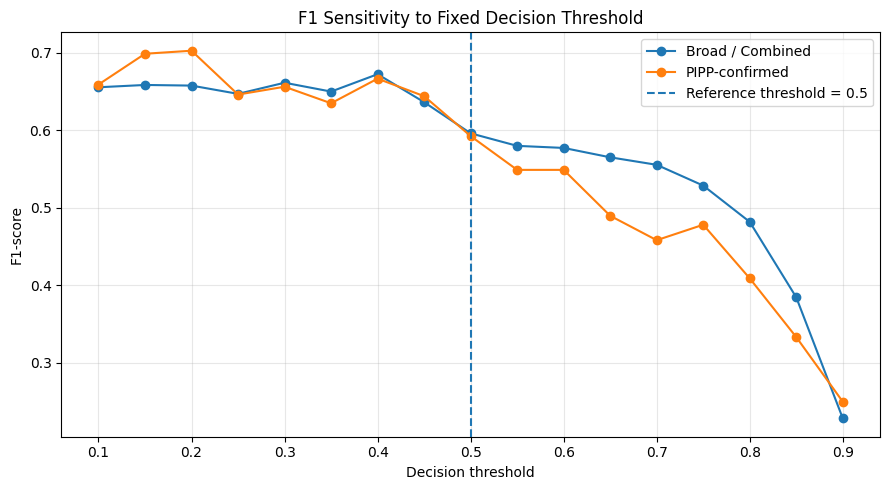

In [16]:
# ============================================================
# THRESHOLD SENSITIVITY PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 5)
)


for dataset_name, group in (
    threshold_df.groupby("dataset")
):

    ax.plot(
        group["threshold"],
        group["f1"],
        marker="o",
        label=dataset_name
    )


ax.axvline(
    0.5,
    linestyle="--",
    linewidth=1.5,
    label="Reference threshold = 0.5"
)


ax.set_xlabel(
    "Decision threshold"
)

ax.set_ylabel(
    "F1-score"
)

ax.set_title(
    "F1 Sensitivity to Fixed Decision Threshold"
)

ax.grid(
    True,
    alpha=0.3
)

ax.legend()

plt.tight_layout()

plt.show()

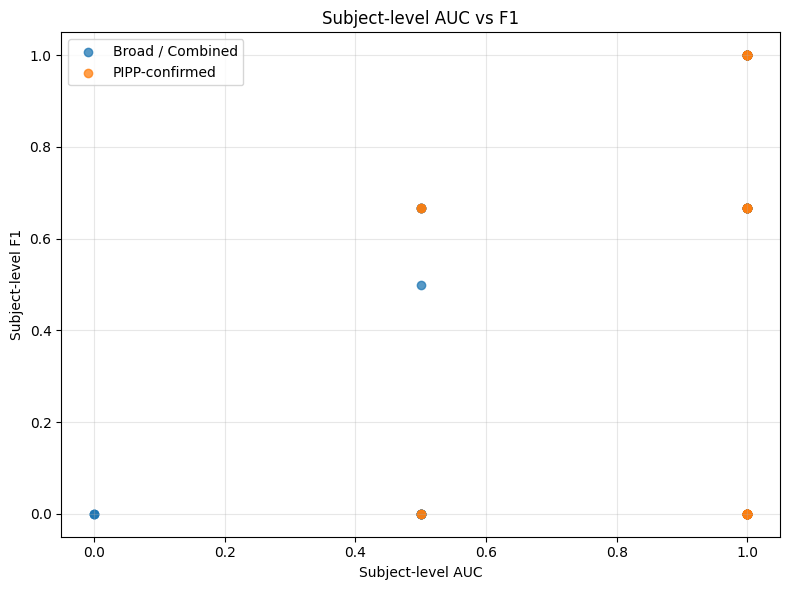

In [17]:
# ============================================================
# SUBJECT-LEVEL AUC VS F1
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.scatter(
    broad_subject_df["auc"],
    broad_subject_df["f1"],
    alpha=0.75,
    label="Broad / Combined"
)


ax.scatter(
    pipp_subject_df["auc"],
    pipp_subject_df["f1"],
    alpha=0.75,
    label="PIPP-confirmed"
)


ax.set_xlabel(
    "Subject-level AUC"
)

ax.set_ylabel(
    "Subject-level F1"
)

ax.set_title(
    "Subject-level AUC vs F1"
)

ax.grid(
    True,
    alpha=0.3
)

ax.legend()

plt.tight_layout()

plt.show()

In [18]:
# ============================================================
# OVERALL SAMPLE COUNTS
# ============================================================

print("=" * 80)
print("OVERALL HELD-OUT SAMPLE COUNTS")
print("=" * 80)

print(
    "Broad pain samples    :",
    int(broad_y_true.sum())
)

print(
    "Broad non-pain samples:",
    int(
        (broad_y_true == 0).sum()
    )
)

print(
    "PIPP pain samples     :",
    int(pipp_y_true.sum())
)

print(
    "PIPP non-pain samples :",
    int(
        (pipp_y_true == 0).sum()
    )
)

OVERALL HELD-OUT SAMPLE COUNTS
Broad pain samples    : 62
Broad non-pain samples: 96
PIPP pain samples     : 34
PIPP non-pain samples : 46


In [19]:
# ============================================================
# SAVE REVIEWER #1 RESULTS
# ============================================================

summary_file = os.path.join(
    RESULTS_PATH,
    "reviewer1_summary_statistics.csv"
)

broad_file = os.path.join(
    RESULTS_PATH,
    "broad_per_subject_metrics.csv"
)

pipp_file = os.path.join(
    RESULTS_PATH,
    "pipp_per_subject_metrics.csv"
)

pooled_file = os.path.join(
    RESULTS_PATH,
    "pooled_auc_summary.csv"
)

threshold_file = os.path.join(
    RESULTS_PATH,
    "threshold_sensitivity.csv"
)

all_subject_file = os.path.join(
    RESULTS_PATH,
    "all_per_subject_metrics.csv"
)


summary_df.to_csv(
    summary_file,
    index=False
)

broad_per_subject.to_csv(
    broad_file,
    index=False
)

pipp_per_subject.to_csv(
    pipp_file,
    index=False
)

pooled_summary_df.to_csv(
    pooled_file,
    index=False
)

threshold_df.to_csv(
    threshold_file,
    index=False
)


all_per_subject = pd.concat(
    [
        broad_per_subject,
        pipp_per_subject
    ],
    ignore_index=True
)

all_per_subject.to_csv(
    all_subject_file,
    index=False
)


print("=" * 80)
print("FILES SAVED")
print("=" * 80)

for filename in sorted(
    os.listdir(RESULTS_PATH)
):

    print(
        os.path.join(
            RESULTS_PATH,
            filename
        )
    )

FILES SAVED
C:\Users\Asus\OneDrive\Desktop\neopain-research\results\reviewer1\all_per_subject_metrics.csv
C:\Users\Asus\OneDrive\Desktop\neopain-research\results\reviewer1\broad_per_subject_metrics.csv
C:\Users\Asus\OneDrive\Desktop\neopain-research\results\reviewer1\pipp_per_subject_metrics.csv
C:\Users\Asus\OneDrive\Desktop\neopain-research\results\reviewer1\pooled_auc_summary.csv
C:\Users\Asus\OneDrive\Desktop\neopain-research\results\reviewer1\reviewer1_summary_statistics.csv
C:\Users\Asus\OneDrive\Desktop\neopain-research\results\reviewer1\threshold_sensitivity.csv


In [20]:
# ============================================================
# FINAL REVIEWER #1 OUTPUT
# ============================================================

print("\n")
print("=" * 90)
print("FINAL REVIEWER #1 DIAGNOSTIC RESULTS")
print("=" * 90)


for summary in [
    broad_summary,
    pipp_summary
]:

    print(
        f"\n{summary['dataset']}"
    )

    print(
        f"Subjects : "
        f"{summary['subjects']}"
    )

    print(
        f"AUC     : "
        f"{summary['mean_auc']:.3f} "
        f"± {summary['sd_auc']:.3f}"
    )

    print(
        f"AUC 95% CI : "
        f"[{summary['auc_ci_low']:.3f}, "
        f"{summary['auc_ci_high']:.3f}]"
    )

    print(
        f"F1      : "
        f"{summary['mean_f1']:.3f} "
        f"± {summary['sd_f1']:.3f}"
    )

    print(
        f"F1 95% CI : "
        f"[{summary['f1_ci_low']:.3f}, "
        f"{summary['f1_ci_high']:.3f}]"
    )


print("\n")
print(
    f"Broad pooled AUC : "
    f"{broad_pooled_auc:.3f}"
)

print(
    f"PIPP pooled AUC  : "
    f"{pipp_pooled_auc:.3f}"
)

print("\n")
print("=" * 90)
print("DO NOT MODIFY THE MANUSCRIPT YET.")
print("Use these diagnostics first to determine the evidence-based response")
print("to Reviewer #1.")
print("=" * 90)



FINAL REVIEWER #1 DIAGNOSTIC RESULTS

Broad / Combined
Subjects : 53
AUC     : 0.849 ± 0.287
AUC 95% CI : [0.770, 0.928]
F1      : 0.475 ± 0.455
F1 95% CI : [0.350, 0.600]

PIPP-confirmed
Subjects : 28
AUC     : 0.929 ± 0.178
AUC 95% CI : [0.859, 0.998]
F1      : 0.452 ± 0.446
F1 95% CI : [0.279, 0.625]


Broad pooled AUC : 0.806
PIPP pooled AUC  : 0.810


DO NOT MODIFY THE MANUSCRIPT YET.
Use these diagnostics first to determine the evidence-based response
to Reviewer #1.
